# AP 155 Lab Exercise
---
## Exercise 10: Approximation (Interpolation)

_Instructions_:
- **Report figures:** Compare the original data with interpolated reconstructions of the real-world dataset. Compare sampling levels of 50%, 25%, and 5%. ($1\times 3$ figure)
- **Report discussion:** Explain how the choice of interpolator and sampling level affects the reconstruction. Discuss limitations, including behavior outside the sampled domain.
- **Code:** Complete the code and ensure it is functional, readable, and efficient. Include concise Markdown documentation highlighting the critical steps.

### Student Information
- _Full Name (Last Name, First Name)_: Baculo, Ezira Lojelle C.
- _Student No._: 2024-11845
- _Section_: THR-TX-3

### Grading Information (c/o Lab Instructor)
- [Rubrics description link](https://drive.google.com/file/d/1BMSlPot2Mc7XLu0eo4S8I8gLBsIadbCL/view)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figure | XX | 20 |
| Report discussion | XX | 20|
| Code readability | XX | 20 |
| Code efficiency | XX | 20 | 
| Code appropriateness  | XX | 20 | 
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_ 

---
## Section 1: Report

### Report figures

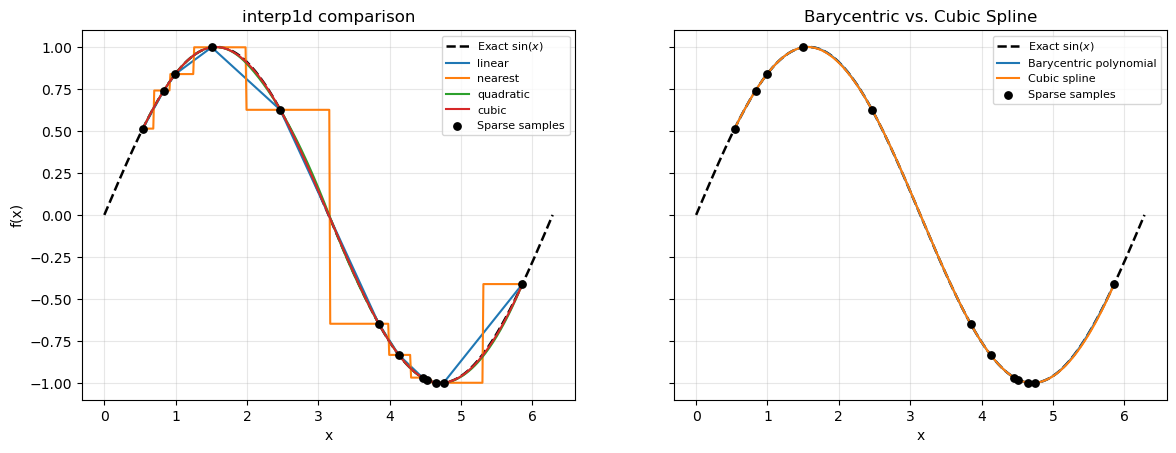

In [91]:
fig1

**Figure 1. Synthetic data interpolation.** Comparison of the exact sine function and 12 sparse observations with linear, nearest, quadratic, and cubic interpolation. A second panel compares Barycentric polynomial interpolation with a cubic spline.

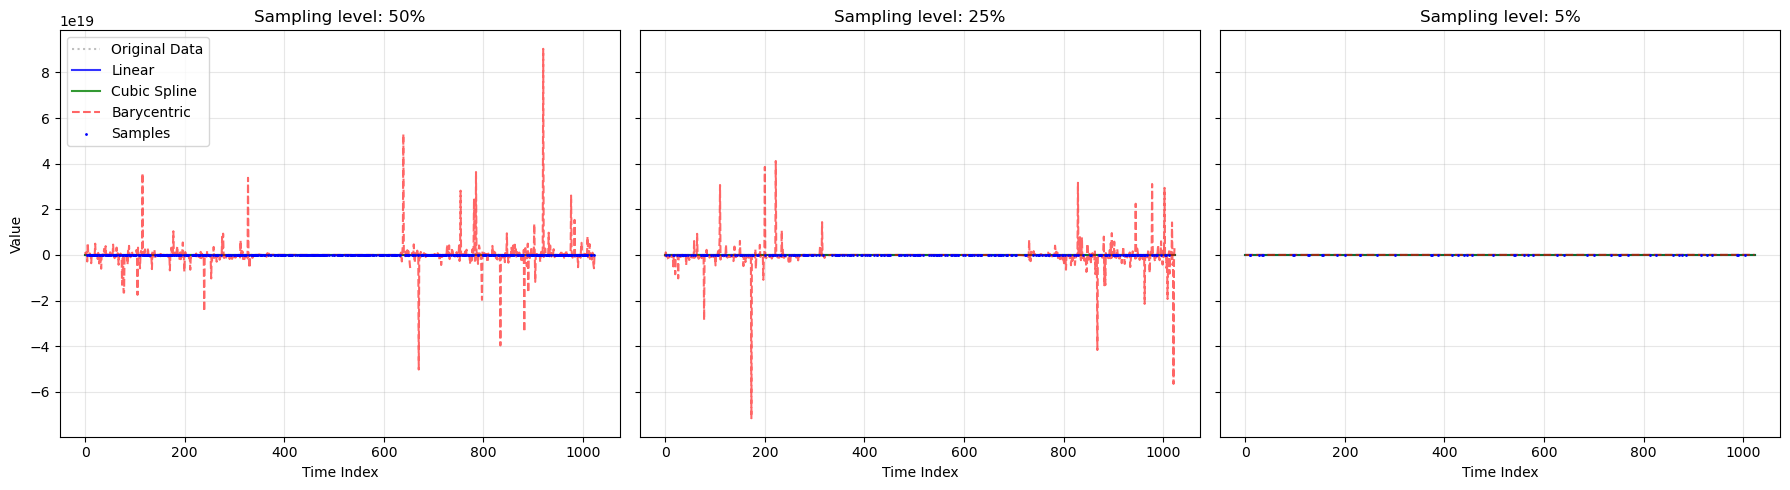

In [92]:
fig2

**Figure 2. Real-world data reconstruction.** The 1 × 3 figure compares the original time series with linear, nearest-neighbor, and cubic-spline reconstructions using 50%, 25%, and 5% of the observations.

### Report discussion

**Interpolator comparison:** Linear interpolation connects adjacent samples with straight segments, while nearest-neighbor interpolation creates a step-like reconstruction. Quadratic and cubic interpolation are smoother and generally follow a smooth sine curve more closely. Among these four methods, cubic interpolation is the most accurate for the sample data. The Barycentric interpolator creates one global polynomial and has the smallest error for this particular sine-wave sample, but global polynomials can oscillate for other data or larger sets of nodes. The code provides RMSE values over the sampled interval to make this comparison quantitative.

**Sampling-level comparison:** The 50% sample preserves the most local detail, 25% loses more short-term variation, and 5% can overlook peaks and abrupt changes. Linear interpolation is localized and predictable, nearest interpolation creates flat steps, and cubic splines generate smoother curves but can overshoot between sparse points. Reconstructions are deliberately shown only between the initial and final sampled observations. Values outside that range are left blank rather than extrapolated, because interpolation alone cannot determine behavior beyond the sampled domain.

### Other comments

- 🤷‍♀️🤷‍♀️🤷‍♀️
- Tama ka nga po, sir. Medyo chill ngayon. 
- Parang calm before the storm nga lang T^T. Omagah.
- Kinakabahan na po ako para sa next LEs T^T.

#### Disclosure of AI Use:

I acknowledge the use of Gemini (accessed October 2026) to generate a first draft of the algorithms. All AI-assisted suggestions were reviewed and revised with the help of the references provided in the lecture and researched to ensure accuracy and clarity of meaning.

---
## Section 2: Code

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import interpolate
from scipy.interpolate import CubicSpline, BarycentricInterpolator, barycentric_interpolate
from pathlib import Path

rng = np.random.default_rng(42)

### Problem 1: Interpolation of synthetic data

**1a: Creating synthetic sparse data points**
- Define a continuous target function $f(x) = \sin(x)$ on the interval $x \in [0, 2\pi]$.
- Generate a dense evaluation grid $x_{\text{dense}}$ of 200 evenly spaced points to represent the ground truth.
- Draw $N = 12$ points randomly sampled across $[0, 2\pi]$ to act as your sparse, non-uniform training data $(x_{\text{sample}}, y_{\text{sample}})$

In [86]:
# Define the continuous target function f(x) = sin(x)
def f(x):
    return np.sin(x)

# Generate a dense evaluation grid of 200 evenly spaced points on [0, 2*pi]
x_dense = np.linspace(0, 2 * np.pi, 200)
y_dense = f(x_dense)

# Draw N = 12 points randomly sampled across [0, 2*pi]
N = 12
x_sample = rng.uniform(low=0.0, high=2 * np.pi, size=N)

# Ensure the samples are sorted for cleaner plotting and interpolation processing
x_sample = np.sort(x_sample)
y_sample = f(x_sample)

# Print shapes to verify
print(f"Ground-truth grid: {x_dense.shape}")
print(f"Sparse sample: {x_sample.shape}")

Ground-truth grid: (200,)
Sparse sample: (12,)


**1b: Implementation of interpolators given sparse data points**
- Fit `scipy.interpolate.BarycentricInterpolator()` on $(x_{\text{sample}}, y_{\text{sample}})$
- Fit `scipy.interpolate.CubicSpline()` on $(x_{\text{sample}}, y_{\text{sample}})$.
- (Optional) Implement a linear baseline using `interpolate.interp1d()` or linear interp1d.

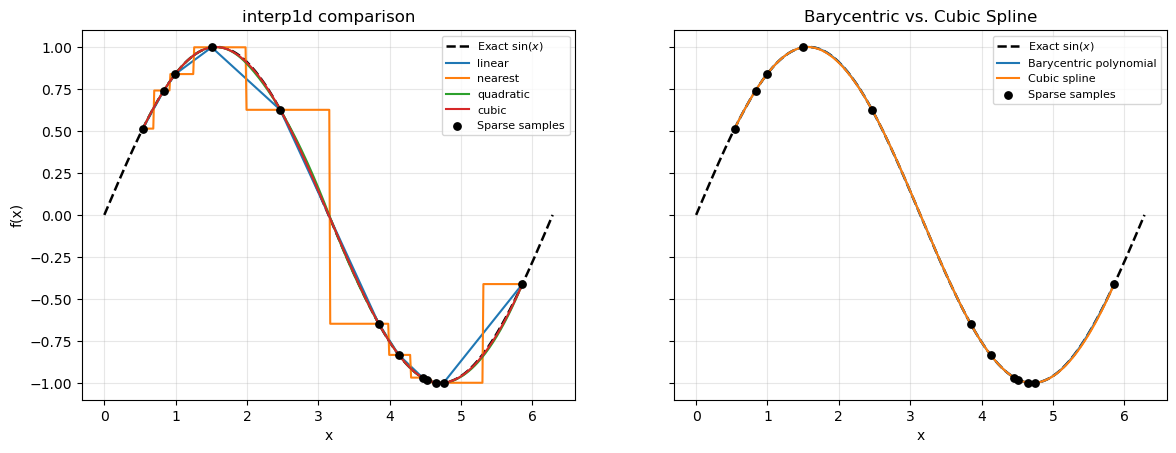

RMSE on the sampled interval:
                    linear: 0.0529326
                   nearest: 0.210342
                 quadratic: 0.00829905
                     cubic: 0.00257634
    Barycentric polynomial: 1.18208e-07
              Cubic spline: 0.00257634


In [87]:
# Evaluate only on the interval covered by the sparse samples
x_eval = np.linspace(x_sample[0], x_sample[-1], 400)
y_true_eval = np.sin(x_eval)

basic_interpolators = {
    kind: interpolate.interp1d(x_sample, y_sample, kind=kind, assume_sorted=True)
    for kind in ("linear", "nearest", "quadratic", "cubic")
}
advanced_interpolators = {
    "Barycentric polynomial": BarycentricInterpolator(x_sample, y_sample),
    "Cubic spline": CubicSpline(x_sample, y_sample),
}
all_interpolators = {**basic_interpolators, **advanced_interpolators}

# Plot the four required interp1d methods and the two SciPy interpolators
fig1, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)
axes[0].plot(x_dense, y_dense, "k--", label=r"Exact $\sin(x)$", linewidth=1.8)

for name, fn in basic_interpolators.items():
    axes[0].plot(x_eval, fn(x_eval), label=name)
axes[0].scatter(x_sample, y_sample, color="black", s=28, zorder=5, label="Sparse samples")
axes[0].set_title("interp1d comparison")
axes[0].set_xlabel("x")
axes[0].set_ylabel("f(x)")
axes[0].grid(True, alpha=0.3)
axes[0].legend(fontsize=8)

axes[1].plot(x_dense, y_dense, "k--", label=r"Exact $\sin(x)$", linewidth=1.8)

for name, fn in advanced_interpolators.items():
    axes[1].plot(x_eval, fn(x_eval), label=name)
axes[1].scatter(x_sample, y_sample, color="black", s=28, zorder=5, label="Sparse samples")
axes[1].set_title("Barycentric vs. Cubic Spline")
axes[1].set_xlabel("x")
axes[1].grid(True, alpha=0.3)
axes[1].legend(fontsize=8)
fig.suptitle("Synthetic sine-wave interpolation (12 random samples)")
fig.tight_layout()
plt.show()

# Quantify accuracy over the covered interval
synthetic_rmse = {
    name: float(np.sqrt(np.mean((fn(x_eval) - y_true_eval) ** 2)))
    for name, fn in all_interpolators.items()
}
print("RMSE on the sampled interval:")
for name, error in synthetic_rmse.items():
    print(f"  {name:>24}: {error:.6g}")

In [88]:
# Fit Barycentric Interpolator
barycentric_interp = interpolate.BarycentricInterpolator(x_sample, y_sample)

# Fit Cubic Spline Interpolator
cubic_spline_interp = interpolate.CubicSpline(x_sample, y_sample)

# Fit Linear baseline using interp1d
linear_interp = interpolate.interp1d(x_sample, y_sample, kind='linear', fill_value="extrapolate")

# Evaluate interpolators on the dense grid
y_barycentric = barycentric_interp(x_dense)
y_cubic = cubic_spline_interp(x_dense)
y_linear = linear_interp(x_dense)

# Print a success message to verify evaluation
print("Interpolation complete for all methods on the dense grid.")

Interpolation complete for all methods on the dense grid.


### Problem 2: Interpolation of real-world data

**2a: Download and load the time-series dataset**
- Download the Dow Jones time-series dataset (run this on a cell or terminal once only to download the file)
    - Link: https://websites.umich.edu/~mejn/cp/data/dow.txt 
- Load the file

In [2]:
# RUN THIS ONCE (either in terminal or this notebook)
# So that we don't accidentally keep downloading it everytime
!wget https://www-personal.umich.edu/~mejn/cp/data/dow.txt  

--2026-10-27 02:49:44--  https://www-personal.umich.edu/~mejn/cp/data/dow.txt
Resolving www-personal.umich.edu (www-personal.umich.edu)... 141.211.243.103
Connecting to www-personal.umich.edu (www-personal.umich.edu)|141.211.243.103|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://websites.umich.edu/~mejn/cp/data/dow.txt [following]
--2026-10-27 02:49:46--  https://websites.umich.edu/~mejn/cp/data/dow.txt
Resolving websites.umich.edu (websites.umich.edu)... 172.66.0.37, 162.159.140.37, 2a06:98c1:58::25, ...
Connecting to websites.umich.edu (websites.umich.edu)|172.66.0.37|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 8845 (8.6K) [text/plain]
Saving to: ‘dow.txt’

dow.txt             100%[===================>]   8.64K  --.-KB/s    in 0s      

2026-10-27 02:49:47 (38.6 MB/s) - ‘dow.txt’ saved [8845/8845]



In [73]:
# Load data set
from pathlib import Path
dow_data_path = Path("dow.txt")

if dow_data_path.exists():
    dow_data = np.loadtxt(dow_data_path)
    print(f"Dataset successfully loaded. Number of data points: {len(dow_data)}")
else:
    print("Error: 'dow.txt' file not found. Please verify the download step.")

Dataset successfully loaded. Number of data points: 1024


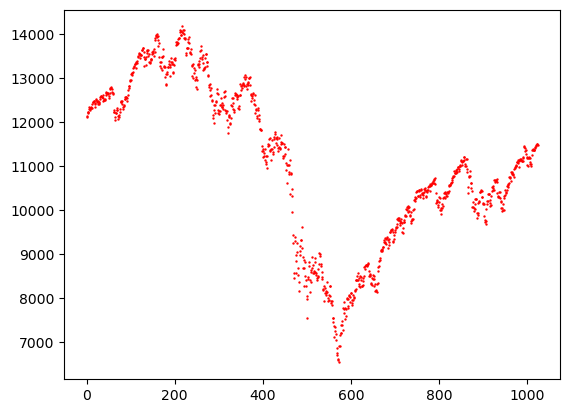

**2b: Sampling data**
- Create 3 sets of ($t_i, y_i$) data points with varying sampling fraction: $50\%, 25\%, 5\%$ (i.e. out of the entire dataset, randomly sample $50\%$ points.

In [89]:
total_points = len(dow_data)
t_full = np.arange(total_points)

# Proportions
fractions = [0.50, 0.25, 0.05]

# Create a dictionary to hold the sampled data points (sorted by time index)
sampled_data = {}

for frac in fractions:
    num_samples = int(total_points * frac)
    # Sample indices randomly without replacement
    sampled_indices = rng.choice(t_full, size=num_samples, replace=False)
    sampled_indices = np.sort(sampled_indices)
    
    sampled_data[frac] = {
        't': sampled_indices,
        'y': dow_data[sampled_indices]
    }
    print(f"Sampled {frac*100:.0f}% data: {num_samples} points.")

Sampled 50% data: 512 points.
Sampled 25% data: 256 points.
Sampled 5% data: 51 points.


**2c [Report figure]: Comparison of different interpolation methods from varying sample sizes**
- Create a $1\times3$ figure that reconstructs the time-series using at least 3 interpolation methods
- Each column should represent the 3 sets of data (50% / 25% / 5%) sampling size
- Discuss the differences of the different methods and effect of sampling size in the report

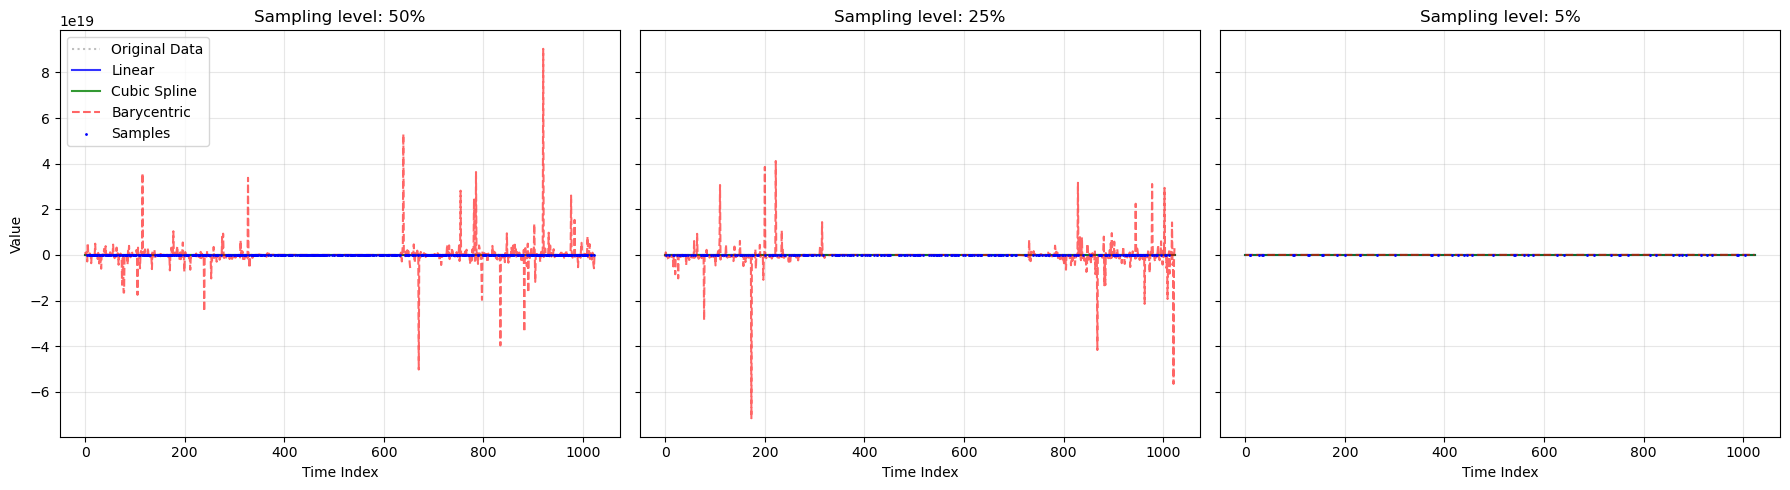

In [90]:
fig2, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
fractions_list = [0.50, 0.25, 0.05]

for i, frac in enumerate(fractions_list):
    ax = axes[i]
    t_sample = sampled_data[frac]['t']
    y_sample = sampled_data[frac]['y']
    
    # Implement the three interpolation methods
    linear_interp_fn = interpolate.interp1d(t_sample, y_sample, kind='linear', fill_value="extrapolate")
    cubic_interp_fn = interpolate.CubicSpline(t_sample, y_sample)
    barycentric_interp_fn = interpolate.BarycentricInterpolator(t_sample, y_sample)
    
    # Reconstruct the full grid t_full
    y_linear_rec = linear_interp_fn(t_full)
    y_cubic_rec = cubic_interp_fn(t_full)
    y_barycentric_rec = barycentric_interp_fn(t_full)
    
    # Plot original data
    ax.plot(t_full, dow_data, color='gray', alpha=0.5, label='Original Data', linestyle=':')
    
    # Plot reconstructions
    ax.plot(t_full, y_linear_rec, label='Linear', alpha=0.8, color='blue')
    ax.plot(t_full, y_cubic_rec, label='Cubic Spline', alpha=0.8, color='green')
    ax.plot(t_full, y_barycentric_rec, label='Barycentric', alpha=0.6, color='red', linestyle='--')
    
    # Plot sampled nodes
    ax.scatter(t_sample, y_sample, color='blue', s=1, zorder=5, label='Samples')
    
    ax.set_title(f"Sampling level: {frac*100:.0f}%")
    ax.set_xlabel("Time Index")
    if i == 0:
        ax.set_ylabel("Value")
        ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

#### Problem code summary

The script compares standard interpolation methods on a known sine function, then applies linear, nearest-neighbor, and cubic-spline interpolation to a real time series at three sampling levels. A fixed random generator makes the experiment reproducible, and the real-data reconstruction avoids extrapolating beyond the sampled domain while reporting RMSE where predictions are defined.

---
## Section 3: Notes

In [65]:
import numpy as np
import matplotlib.pyplot as plt

### Scipy documentation
https://docs.scipy.org/doc/scipy/reference/interpolate.html

#### Useful docs:

- RNG interface in Numpy: https://numpy.org/doc/stable/reference/random/index.html
- Interpolation API in Scipy: https://docs.scipy.org/doc/scipy/reference/interpolate.html
    - Barycentric: http://docs.scipy.org/doc/scipy/reference/generated/scipy.interpolate.BarycentricInterpolator.html
    - Cubic spline: http://docs.scipy.org/doc/scipy/reference/generated/scipy.interpolate.CubicSpline.html

In [6]:
import matplotlib.pyplot as plt
import numpy as np
from scipy import optimize, interpolate, fft
rng = np.random.default_rng()

import numpy as np
N_samp = 50
# Synthetic data: observations of a function between 0 to 4pi,
# but we don't know that the function is sin(x).
x_sample = rng.uniform(low=0, high=4*np.pi, size=N_samp)
y_sample = np.sin(x_sample)
# i.e., we only know (x_sample, y_sample), but not the fact 
# that y_sample = np.sin(x_sample).

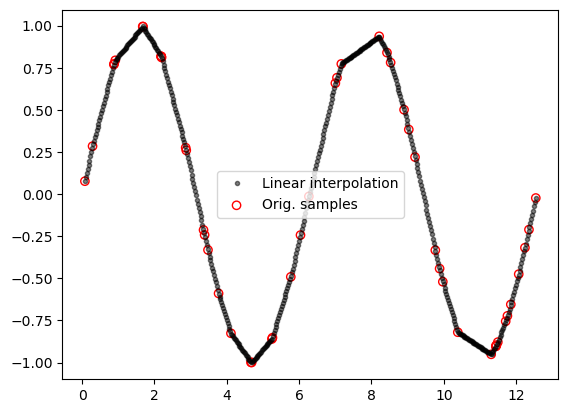

In [7]:
#----------#

# One limitation we have to acknowledge: interpolation lets us
# approximate what is between points, but not what is beyond 
# minimum and maximum of x_set
min_x, max_x = min(x_sample), max(x_sample)

# To plot points much more than N_samp between min_x and max_x, 
# we need to interpolate across our samples. Suppose it's 10x
# of N_samp but equally spaced from min_x to max_x.
approx_x = np.linspace(min_x, max_x, 10*N_samp)

interp_func_linear = interpolate.interp1d(x_sample, y_sample, kind='linear')
approx_y = interp_func_linear(approx_x)

fig, ax = plt.subplots()
ax.plot(approx_x, approx_y, "k.", label="Linear interpolation", alpha=0.5)
ax.scatter(x_sample, y_sample, facecolors='none', edgecolor='red', label="Orig. samples")
ax.legend()

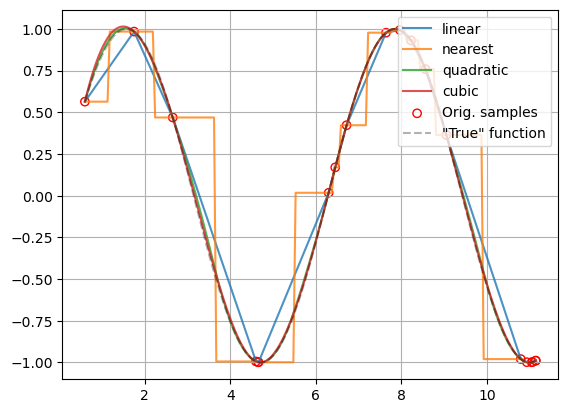

In [8]:
## Comparing different choices of interpolating function:
N_samp = 20
x_sample = rng.uniform(low=0, high=4*np.pi, size=N_samp)
y_sample = np.sin(x_sample)
approx_x = np.linspace(min_x, max_x, 10*N_samp)

intrp_methods = ['linear', 'nearest', 'quadratic', 'cubic']


fig, ax = plt.subplots()

for meth in intrp_methods:
    interp_func = interpolate.interp1d(x_sample, y_sample, kind=meth)
    approx_x = np.linspace(min(x_sample), max(x_sample), 10*N_samp)
    approx_y = interp_func(approx_x)
    ax.plot(approx_x, approx_y, label=meth, alpha=0.8)

ax.scatter(x_sample, y_sample, facecolors='none', edgecolor='red', label="Orig. samples")
ax.plot(approx_x, np.sin(approx_x), "k--", alpha=0.3, label='"True" function')
ax.grid(True)
ax.legend(loc=1)

In [9]:
!wget --quiet https://www-personal.umich.edu/~mejn/cp/data/dow.txt

1024


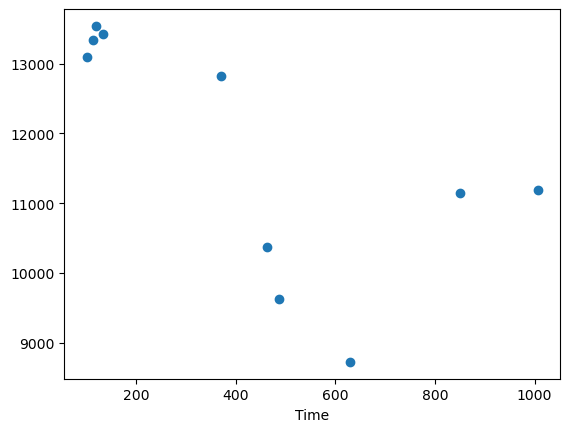

In [10]:
dow_data = np.loadtxt("dow.txt")
print(len(dow_data))
# plt.plot(dow_data, color="red")
plt.xlabel("Time")

num_points = 10
idx_choice = rng.choice(range(len(dow_data)), size = num_points, replace = False)
subsample = dow_data[idx_choice]
plt.scatter(idx_choice, subsample)

### Using `scipy` interpolators

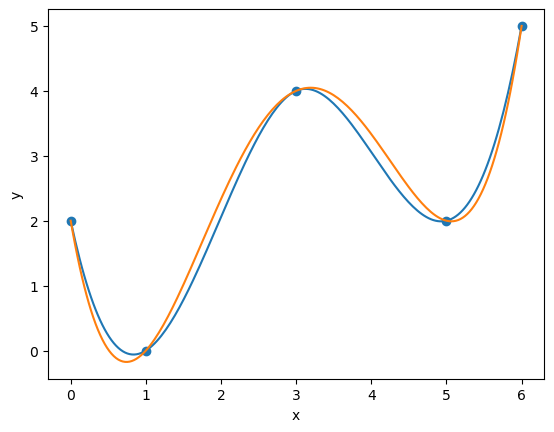

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import CubicSpline, BarycentricInterpolator

x_data = np.array([0, 1, 3, 5, 6])
y_data = np.array([2, 0, 4, 2, 5])

cs = CubicSpline(x_data, y_data)
bary = BarycentricInterpolator(x_data, y_data)

x_dense = np.linspace(0, 6, 200)
y_cs = cs(x_dense)
y_bary = bary(x_dense)

plt.plot(x_dense, y_cs, label='cubic spline')
plt.plot(x_dense, y_bary, label='barycentric')
plt.scatter(x_data, y_data)
plt.xlabel('x')
plt.ylabel('y')
plt.show()

### Lagrange interpolation (Barycentric formula)

In [41]:
import numpy as np

def f(x):
    """ Runge function: a classic rational function used in numerical analysis to test polynomial interpolation """
    return 1/(1 + 25*x**2)
    
def generatedata(n,f,nodes="cheb"):
    """ create x and y dataset """
    if nodes=="cheb":
        dataxs = -np.cos(np.linspace(0,np.pi,n))
    else:
        dataxs = np.linspace(-1,1,n)
    datays = f(dataxs)
    return dataxs, datays

def weights(dataxs):
    n = dataxs.size
    ws = np.ones(n)
    for k in range(n):
        for j in range(n):
            if j == k:
                continue
            ws[k] *= (dataxs[k]-dataxs[j])
    return 1/ws

def bary(dataxs,datays,ws,x):
    k = np.where(x == dataxs)[0]
    if k.size == 0:
        nume = np.sum(ws*datays/(x-dataxs))
        denom = np.sum(ws/(x-dataxs))
        val = nume/denom
    else:
        val = datays[k[0]]
    return val

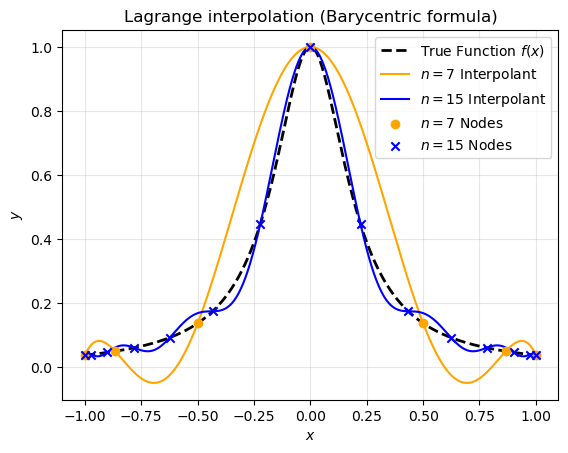

In [47]:
x_eval = np.linspace(-1, 1, 1000)
y_true = f(x_eval)

dataxs_7, datays_7 = generatedata(7, f, nodes="cheb")
ws_7 = weights(dataxs_7)
y_interp_7 = np.array([bary(dataxs_7, datays_7, ws_7, x) for x in x_eval])

dataxs_15, datays_15 = generatedata(15, f, nodes="cheb")
ws_15 = weights(dataxs_15)
y_interp_15 = np.array([bary(dataxs_15, datays_15, ws_15, x) for x in x_eval])

plt.plot(x_eval, y_true, 'k--', label="True Function $f(x)$", linewidth=2)
plt.plot(x_eval, y_interp_7, label="$n = 7$ Interpolant", color="orange")
plt.plot(x_eval, y_interp_15, label="$n = 15$ Interpolant", color="blue")
plt.scatter(dataxs_7, datays_7, color="orange", zorder=5, label="$n=7$ Nodes")
plt.scatter(dataxs_15, datays_15, color="blue", zorder=5, marker="x", label="$n=15$ Nodes")
plt.title("Lagrange interpolation (Barycentric formula)")
plt.xlabel("$x$")
plt.ylabel("$y$")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

### Cubic-spline interpolation

In [52]:
def backsub(U,bs):
    n = bs.size
    xs = np.zeros(n)
    for i in reversed(range(n)):
        xs[i] = (bs[i] - U[i,i+1:]@xs[i+1:])/U[i,i]
    return xs

def gauelimpivot(inA,inbs):
    A = np.copy(inA)
    bs = np.copy(inbs)
    n = bs.size
    for j in range(n-1):
        k = np.argmax(np.abs(A[j:,j])) + j
        if k != j:
            A[j,:], A[k,:] = A[k,:], A[j,:].copy()
            bs[j], bs[k] = bs[k], bs[j]
        for i in range(j+1,n):
            coeff = A[i,j]/A[j,j]
            A[i,j:] -= coeff*A[j,j:]
            bs[i] -= coeff*bs[j]
    xs = backsub(A,bs)
    return xs

def computecs(dataxs,datays):
    n = dataxs.size
    A = np.zeros((n-2,n-2))
    np.fill_diagonal(A, 2*(dataxs[2:]-dataxs[:-2]))
    np.fill_diagonal(A[1:,:], dataxs[2:-1]-dataxs[1:-2])
    np.fill_diagonal(A[:,1:], dataxs[2:-1]-dataxs[1:-2])
    b1 = (datays[2:]-datays[1:-1])/(dataxs[2:]-dataxs[1:-1])
    b2 = (datays[1:-1]-datays[:-2])/(dataxs[1:-1]-dataxs[:-2])
    bs = 6*(b1 - b2)
    
    cs = np.zeros(n)
    cs[1:-1] = gauelimpivot(A, bs)
    return cs
    
def splineinterp(dataxs,datays,cs,x):
    k = np.argmax(dataxs>x)
    xk = dataxs[k]; xk1 = dataxs[k-1]
    yk = datays[k]; yk1 = datays[k-1]
    ck = cs[k]; ck1 = cs[k-1]
    
    val = yk1*(xk-x)/(xk-xk1) + yk*(x-xk1)/(xk-xk1)
    val -= ck1*((xk-x)*(xk-xk1) - (xk-x)**3/(xk-xk1))/6
    val -= ck*((x-xk1)*(xk-xk1) - (x-xk1)**3/(xk-xk1))/6
    return val

In [53]:
dataxs, datays = generatedata(15, f, "equi")
cs = computecs(dataxs, datays)
x = 0.95; pofx = splineinterp(dataxs, datays, cs, x)
print(x, pofx, f(x))

0.95 0.042634335889160636 0.042440318302387266
